In [29]:
# Import the necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set visualization preferences
%matplotlib inline

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("Libraries imported successfully!")

Libraries imported successfully!


In [30]:
# Read the mathematics student dataset

df = pd.read_csv(
    'data/student-mat.csv',
    sep=';'
)
# Make the cleaned copy (removes students with G3 = 0)
df_clean = df[df["G3"] > 0].copy()

# Convert only the nominal variables to category
nominal_columns = [
    'school', 'sex', 'address', 'famsize', 'Pstatus',
    'Mjob', 'Fjob', 'reason', 'guardian',
    'schoolsup', 'famsup', 'paid', 'activities',
    'nursery', 'higher', 'internet', 'romantic'
]
df_clean[nominal_columns] = df_clean[nominal_columns].astype('category')

print(df.shape, df_clean.shape)

# Display the first five records
df.head()

(395, 33) (357, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


In [31]:
print("Number of rows and columns:")
print(df.shape)

Number of rows and columns:
(395, 33)


In [32]:
print("Column names:")
print(df.columns.tolist())

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [34]:
# Check the number of duplicate rows
df.duplicated().sum()

np.int64(0)

In [35]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [36]:
print(df_clean[["G3", "studytime", "absences"]].describe())

               G3   studytime    absences
count  357.000000  357.000000  357.000000
mean    11.523810    2.042017    6.316527
std      3.227797    0.831895    8.187623
min      4.000000    1.000000    0.000000
25%      9.000000    1.000000    2.000000
50%     11.000000    2.000000    4.000000
75%     14.000000    2.000000    8.000000
max     20.000000    4.000000   75.000000


In [37]:
df_clean.groupby("studytime")["G3"].agg(["count", "mean", "std"]).round(2)

,count,mean,std
studytime,,,
1,92,11.47,3.41
2,182,11.07,3.07
3,59,12.56,2.99
4,24,12.67,3.60


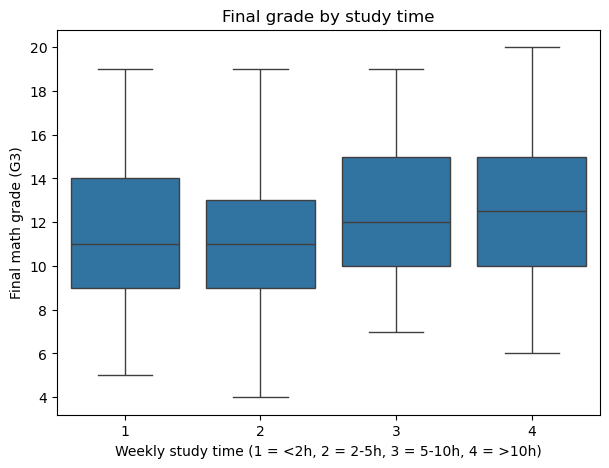

In [38]:
#Research Question 1: Does study time influence mathematics performance?
plt.figure(figsize=(7, 5))
sns.boxplot(x="studytime", y="G3", data=df_clean)
plt.xlabel("Weekly study time (1 = <2h, 2 = 2-5h, 3 = 5-10h, 4 = >10h)")
plt.ylabel("Final math grade (G3)")
plt.title("Final grade by study time")
plt.show()

In [39]:
# Kruskal-Wallis: do the four study-time groups differ?
groups = [g["G3"] for _, g in df_clean.groupby("studytime")]
h_stat, p_kw = stats.kruskal(*groups)
print("Kruskal-Wallis H =", round(h_stat, 3), ", p =", round(p_kw, 4))

# Spearman: strength and direction of the relationship
rho, p_sp = stats.spearmanr(df_clean["studytime"], df_clean["G3"])
print("Spearman rho =", round(rho, 3), ", p =", round(p_sp, 4))

Kruskal-Wallis H = 11.181 , p = 0.0108
Spearman rho = 0.11 , p = 0.038


In [40]:
# Post-hoc pairwise Mann-Whitney U tests to see which study-time groups differ,
# using a Bonferroni-corrected threshold (0.05 / 6 pairs = 0.0083)

from itertools import combinations

for a, b in combinations([1, 2, 3, 4], 2):
    x = df_clean[df_clean["studytime"] == a]["G3"]
    y = df_clean[df_clean["studytime"] == b]["G3"]
    u, p = stats.mannwhitneyu(x, y)
    print(f"Group {a} vs {b}: p = {p:.4f}")

Group 1 vs 2: p = 0.4106
Group 1 vs 3: p = 0.0492
Group 1 vs 4: p = 0.1540
Group 2 vs 3: p = 0.0030
Group 2 vs 4: p = 0.0415
Group 3 vs 4: p = 0.9356


## Research Question 1: Does study time influence mathematics performance?

**Method.** Students with a final grade (G3) of 0 were removed before analysis (38 of 395), leaving 357 students. Weekly study time is an ordered scale (1 = under 2 hours, 2 = 2 to 5 hours, 3 = 5 to 10 hours, 4 = over 10 hours), and the group sizes are uneven, so non-parametric tests were used. A Kruskal-Wallis test compared G3 across the four study-time groups, and a Spearman rank correlation measured the strength and direction of the relationship.

**Descriptive results.**

| Study time | n | Mean G3 | SD |
|---|---|---|---|
| Under 2 hours | 92 | 11.47 | 3.41 |
| 2 to 5 hours | 182 | 11.07 | 3.07 |
| 5 to 10 hours | 59 | 12.56 | 2.99 |
| Over 10 hours | 24 | 12.67 | 3.60 |

**Inferential results.**
- Kruskal-Wallis: H = 11.18, p = 0.011. The final grade distributions differ significantly across study-time groups.
- Spearman correlation: ρ = 0.11, p = 0.038. There is a weak positive association between study time and final grade.
- 2 vs 3 is the only pair that survives the correction. Students studying 2 to 5 hours score significantly lower than those studying 5 to 10 hours.
1 vs 3 (p = 0.049) and 2 vs 4 (p = 0.042) are borderline. They would count at the usual 0.05 level, but not after correcting for six comparisons. In your write-up, call them “suggestive but not significant after correction”.
3 vs 4 (p = 0.94) shows the two highest-studying groups are essentially the same. The step up in grades happens at 5 hours, and studying more than 10 hours adds nothing on top.

**Interpretation.** Study time is significantly associated with mathematics performance, but the relationship is weak. Study time alone explains only about 1% of the variation in grades (ρ² ≈ 0.01). The pattern is not a steady increase: students studying 2 to 5 hours scored slightly below those studying under 2 hours, and the higher grades appear only among students studying 5 hours or more (means of about 12.6 and 12.7, compared with about 11.1 to 11.5 in the other two groups).

**Limitations.** The data are observational, so the result shows an association, not that studying more causes higher grades. The over-10-hour group is small (n = 24), so its mean is less stable than the others. Study time is also self-reported in broad bands, not measured hours.

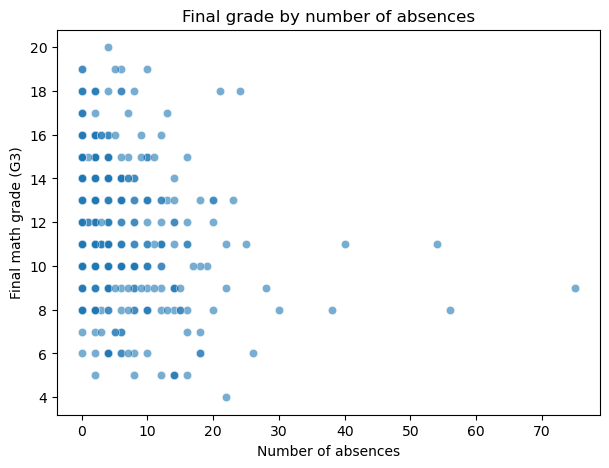

In [41]:
#Research Question 2: Is there a relationship between school attendance and mathematics achievement?
#School attendence relation to mathematics achievement
plt.figure(figsize=(7, 5))
sns.scatterplot(x="absences", y="G3", data=df_clean, alpha=0.6)
plt.xlabel("Number of absences")
plt.ylabel("Final math grade (G3)")
plt.title("Final grade by number of absences")
plt.show()

In [42]:
# Spearman rank correlation: absences vs final grade
rho, p = stats.spearmanr(df_clean["absences"], df_clean["G3"])
print("Spearman rho =", round(rho, 3), ", p =", round(p, 6))

Spearman rho = -0.244 , p = 3e-06


In [43]:
# Group absences into bands to compare mean grades
df_clean["abs_band"] = pd.cut(df_clean["absences"], bins=[-1, 0, 4, 10, 100],
                              labels=["0", "1-4", "5-10", "11+"])
df_clean.groupby("abs_band", observed=True)["G3"].agg(["count", "mean", "std"]).round(2)

,count,mean,std
abs_band,,,
0,77,12.61,3.09
1-4,129,11.65,3.01
5-10,85,11.41,3.36
11+,66,10.15,3.18


## Research Question 2: Is there a relationship between school attendance and mathematics achievement?

**Method.** The number of school absences is a skewed count (median = 4, mean = 6.3, maximum = 75), so a Spearman rank correlation was used instead of Pearson. Absences were also grouped into four bands (0, 1 to 4, 5 to 10, and 11 or more) to compare mean grades. The analysis used the 357 students remaining after removing those with a final grade of 0.

**Descriptive results.**

| Absences | n | Mean G3 | SD |
|---|---|---|---|
| 0 | 77 | 12.61 | 3.09 |
| 1 to 4 | 129 | 11.65 | 3.01 |
| 5 to 10 | 85 | 11.41 | 3.36 |
| 11 or more | 66 | 10.15 | 3.18 |

**Inferential results.** Spearman correlation: ρ = -0.244, p < 0.001. There is a significant negative association between absences and final grade.

**Interpretation.** Students with more absences tend to have lower mathematics grades. The relationship is weak to moderate: absences account for about 6% of the variation in grades (ρ² ≈ 0.06). Mean grades fall from 12.61 for students with no absences to 10.15 for those with 11 or more, a difference of about 2.5 points.

**Limitations.** The data are observational, so the result shows an association, not that missing school causes lower grades. Students who struggle with mathematics may also be more likely to skip class. Students with a final grade of 0 were removed because they all had 0 recorded absences, which likely reflects missing records, not perfect attendance.

In [44]:
#Research Question 3: Does parental educational background influence mathematics performance?
# Mean final grade by mother's and father's education level
print(df_clean.groupby("Medu")["G3"].agg(["count", "mean"]).round(2))
print(df_clean.groupby("Fedu")["G3"].agg(["count", "mean"]).round(2))

      count   mean
Medu              
0         3  13.00
1        50  10.24
2        89  11.26
3        90  11.33
4       125  12.33
      count   mean
Fedu              
0         2  13.00
1        71  10.58
2       102  11.57
3        94  11.34
4        88  12.40


In [45]:
for col in ["Medu", "Fedu"]:
    rho, p = stats.spearmanr(df_clean[col], df_clean["G3"])
    print(col, ": rho =", round(rho, 3), ", p =", round(p, 4))
    

Medu : rho = 0.192 , p = 0.0003
Fedu : rho = 0.164 , p = 0.0019


In [46]:
#check the two parents against each other
rho, p = stats.spearmanr(df_clean["Medu"], df_clean["Fedu"])
print("Medu vs Fedu: rho =", round(rho, 3), ", p =", round(p, 6))

Medu vs Fedu: rho = 0.617 , p = 0.0


In [47]:
# Merge level 0 into level 1 ("primary or none") because levels 0 have only 2-3 students
df_clean["Medu_grp"] = df_clean["Medu"].clip(lower=1)
df_clean["Fedu_grp"] = df_clean["Fedu"].clip(lower=1)

for col in ["Medu_grp", "Fedu_grp"]:
    print(df_clean.groupby(col)["G3"].agg(["count", "mean", "std"]).round(2))
    groups = [g["G3"] for _, g in df_clean.groupby(col)]
    h, p = stats.kruskal(*groups)
    print(col, ": Kruskal-Wallis H =", round(h, 3), ", p =", round(p, 4), "\n")

          count   mean   std
Medu_grp                    
1            53  10.40  2.60
2            89  11.26  2.74
3            90  11.33  3.42
4           125  12.33  3.48
Medu_grp : Kruskal-Wallis H = 14.821 , p = 0.002 

          count   mean   std
Fedu_grp                    
1            73  10.64  3.01
2           102  11.57  3.16
3            94  11.34  3.24
4            88  12.40  3.29
Fedu_grp : Kruskal-Wallis H = 13.83 , p = 0.0031 



In [48]:
# Mean final grade for each combination of mother's and father's education
print(df_clean.pivot_table(values="G3", index="Medu_grp", columns="Fedu_grp", aggfunc="mean").round(2))

# Number of students in each combination
print(pd.crosstab(df_clean["Medu_grp"], df_clean["Fedu_grp"]))

Fedu_grp      1      2      3      4
Medu_grp                            
1         10.06  11.33   9.00  13.00
2         11.22  11.07  11.19  12.71
3         11.27  11.56  10.81  12.36
4          9.00  12.89  12.16  12.36
Fedu_grp   1   2   3   4
Medu_grp                
1         33  15   4   1
2         23  43  16   7
3         15  25  36  14
4          2  19  38  66


## Research Question 3: Does parental educational background influence mathematics performance?

**Method.** Mother's education (Medu) and father's education (Fedu) are ordered scales (0 = none, 1 = primary, 2 = 5th to 9th grade, 3 = secondary, 4 = higher education). Level 0 had only 3 mothers and 2 fathers, so it was merged with level 1 to form a "primary education or none" group for each parent. Spearman rank correlations were used to measure the relationship with final grade (G3), and Kruskal-Wallis tests compared G3 across the four education groups. The correlation between the two parents' education levels was also checked, and mean grades were compared across combinations of mother's and father's education. The analysis used the 357 students remaining after removing those with a final grade of 0.

**Descriptive results.**

| Education level | Mother: n | Mother: mean G3 | Father: n | Father: mean G3 |
|---|---|---|---|---|
| Primary or none | 53 | 10.40 | 73 | 10.64 |
| 5th to 9th grade | 89 | 11.26 | 102 | 11.57 |
| Secondary | 90 | 11.33 | 94 | 11.34 |
| Higher education | 125 | 12.33 | 88 | 12.40 |

**Inferential results.**
- Spearman correlation with G3: mother's education ρ = 0.192 (p < 0.001); father's education ρ = 0.164 (p = 0.002).
- Kruskal-Wallis: mother's education H = 14.82 (p = 0.002); father's education H = 13.83 (p = 0.003).
- Mother's and father's education were strongly correlated with each other (ρ = 0.617, p < 0.001).

**Interpretation.** Students whose parents have more education tend to achieve higher mathematics grades. For both parents, mean grades rise from about 10.4 to 10.6 in the lowest education group to about 12.3 to 12.4 in the highest, a difference of roughly 1.8 to 1.9 points. The relationships are weak: mother's education accounts for about 3.7% of the variation in grades (ρ² ≈ 0.037) and father's for about 2.7% (ρ² ≈ 0.027). For fathers, the pattern is not perfectly steady, since the secondary group (11.34) scored slightly below the 5th to 9th grade group (11.57), and the clear gain appears only at higher education.

Because the parents' education levels are strongly related, the separate correlations cannot show which parent matters more. In the cross-tabulation of mean grades, mother's education was associated with higher grades in most columns when father's education was held fixed, whereas father's education showed no consistent pattern when mother's education was held fixed. This suggests that mother's education may be the stronger factor, but it is only suggestive, because several combinations contain very few students (for example, n = 1 to 7).

**Limitations.** The data are observational, so the results show associations, not that parental education causes higher grades. Parental education is likely to be linked to other factors, such as household income and access to resources, that were not measured. Several cells in the cross-tabulation are too small to interpret reliably.

In [49]:
#Question 4: Do students receiving additional academic support perform better?
# Mean final grade for students with and without each type of support
for col in ["schoolsup", "famsup", "paid"]:
    print(df_clean.groupby(col, observed=True)["G3"].agg(["count", "mean", "std"]).round(2), "\n")

           count   mean   std
schoolsup                    
no           307  11.83  3.22
yes           50   9.62  2.55 

        count   mean   std
famsup                    
no        138  11.80  3.18
yes       219  11.35  3.25 

      count   mean   std
paid                    
no      184  11.61  3.40
yes     173  11.43  3.04 



In [50]:
# Mann-Whitney U test: do students with and without support differ in final grade?
for col in ["schoolsup", "famsup", "paid"]:
    yes = df_clean[df_clean[col] == "yes"]["G3"]
    no = df_clean[df_clean[col] == "no"]["G3"]
    u, p = stats.mannwhitneyu(yes, no)
    print(col, ": U =", u, ", p =", round(p, 4))

schoolsup : U = 4638.5 , p = 0.0
famsup : U = 13952.5 , p = 0.2203
paid : U = 15418.5 , p = 0.6082


In [51]:
# Compare first-period grades (G1) for students with and without school support
print(df_clean.groupby("schoolsup", observed=True)["G1"].agg(["count", "mean", "std"]).round(2))

# Compare how much grades changed from the first period to the final grade
df_clean["change"] = df_clean["G3"] - df_clean["G1"]
print(df_clean.groupby("schoolsup", observed=True)["change"].agg(["count", "mean", "std"]).round(2))

# Test the change in grade
yes = df_clean[df_clean["schoolsup"] == "yes"]["change"]
no = df_clean[df_clean["schoolsup"] == "no"]["change"]
print(stats.mannwhitneyu(yes, no))

           count   mean   std
schoolsup                    
no           307  11.62  3.24
yes           50   9.12  2.31
           count  mean   std
schoolsup                   
no           307  0.21  1.44
yes           50  0.50  1.84
MannwhitneyuResult(statistic=np.float64(8339.5), pvalue=np.float64(0.31619824016524545))


## Research Question 4: Do students receiving additional academic support perform better?

**Method.** Three binary support variables were compared: extra educational support from the school (schoolsup), educational support from the family (famsup), and extra paid mathematics classes (paid). For each, final grades (G3) of students with and without support were compared using Mann-Whitney U tests. Because students receiving school support may differ from the others before support begins, first-period grades (G1) and the change in grade from G1 to G3 were also compared. The analysis used the 357 students remaining after removing those with a final grade of 0.

**Descriptive results.**

| Support type | Group | n | Mean G3 | SD |
|---|---|---|---|---|
| School support | No | 307 | 11.83 | 3.22 |
| School support | Yes | 50 | 9.62 | 2.55 |
| Family support | No | 138 | 11.80 | 3.18 |
| Family support | Yes | 219 | 11.35 | 3.25 |
| Paid classes | No | 184 | 11.61 | 3.40 |
| Paid classes | Yes | 173 | 11.43 | 3.04 |

**Inferential results.**
- School support: U = 4638.5, p < 0.001. Students receiving school support had significantly lower final grades.
- Family support: U = 13952.5, p = 0.220. No significant difference.
- Paid classes: U = 15418.5, p = 0.608. No significant difference.
- First-period grades (G1) were lower for students receiving school support (mean 9.12) than for those who did not (mean 11.62).
- The change in grade from G1 to G3 did not differ significantly between students with school support (mean +0.50) and without it (mean +0.21), U = 8339.5, p = 0.316.

**Interpretation.** No type of additional support was associated with higher final grades. School support was associated with markedly lower grades, but this reflects who receives it, not a harmful effect: students receiving school support already had lower first-period grades, by about 2.5 points, and the gap in final grades (about 2.2 points) was similar. Their gain from the first period to the final grade was not significantly different from that of other students. Family support and paid classes showed no meaningful difference in final grades.

**Limitations.** The data are observational and support is not assigned at random, so the comparisons cannot show whether support improves performance. Weaker

In [52]:
import sklearn
print(sklearn.__version__)

1.7.2


In [53]:
from sklearn.model_selection import train_test_split

# Use only the original columns, so the extra columns we created
# (abs_band, Medu_grp, Fedu_grp, change) are not included
features = [c for c in df.columns if c not in ["G1", "G2", "G3"]]

# Convert text categories to 0/1 columns so the model can use them
X = pd.get_dummies(df_clean[features], drop_first=True).astype(float)
y = df_clean["G3"]

# 80% of students to train the model, 20% held back to test it
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X.shape, X_train.shape, X_test.shape)

(357, 39) (285, 39) (72, 39)


In [54]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Fit both models on the training students
lr = LinearRegression().fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=300, random_state=42).fit(X_train, y_train)

# Evaluate each one on the 72 held-back test students
for name, model in [("Linear regression", lr), ("Random forest", rf)]:
    pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    print(name, ": RMSE =", round(rmse, 2), ", R2 =", round(r2_score(y_test, pred), 3))

Linear regression : RMSE = 2.77 , R2 = 0.202
Random forest : RMSE = 2.72 , R2 = 0.233


In [55]:
from sklearn.model_selection import cross_val_score, KFold

# 5-fold cross-validation: train and test on five different splits, then average R2
cv = KFold(n_splits=5, shuffle=True, random_state=1)
scores = cross_val_score(RandomForestRegressor(n_estimators=300, random_state=42), X, y, cv=cv, scoring="r2")
print("R2 for each fold:", scores.round(3))
print("Mean R2:", round(scores.mean(), 3))

R2 for each fold: [0.024 0.267 0.17  0.106 0.253]
Mean R2: 0.164


absences         0.105
failures         0.068
health           0.064
studytime        0.056
schoolsup_yes    0.050
Walc             0.048
age              0.048
goout            0.045
famrel           0.042
freetime         0.042
dtype: float64


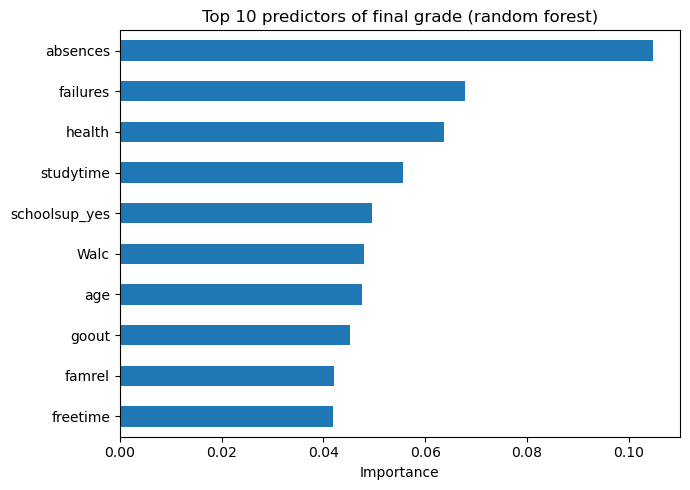

In [56]:
# Importance of each variable in the random forest (fitted on the training students in Step 21)
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importance.head(10).round(3))

# Bar chart of the top 10
plt.figure(figsize=(7, 5))
importance.head(10).sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.title("Top 10 predictors of final grade (random forest)")
plt.tight_layout()
plt.show()

## Research Question 5: Can final mathematics grades be predicted from academic and demographic characteristics?

**Method.** The 39 predictor variables (after converting categorical variables to indicator columns) included demographic, family, school and behavioural characteristics. The earlier period grades (G1 and G2) were excluded, because they are closely tied to the final grade and would make prediction trivial. The 357 students were split randomly into a training set (n = 285) and a test set (n = 72). Linear regression and a random forest (300 trees) were fitted on the training set and evaluated on the test set using root mean squared error (RMSE) and R². Five-fold cross-validation was also used to check stability, and random forest feature importance was used to rank the predictors.

**Results.**

| Model | RMSE | R² (test set) |
|---|---|---|
| Linear regression | 2.77 | 0.202 |
| Random forest | 2.72 | 0.233 |

- Five-fold cross-validation of the random forest gave R² values of 0.024, 0.267, 0.170, 0.106 and 0.253 (mean = 0.164).
- The most important predictors in the random forest were absences (0.105), past failures (0.068), health (0.064), study time (0.056) and school support (0.050), followed by weekend alcohol use, age, going out with friends, family relationships and free time (each 0.042 to 0.048).

**Interpretation.** Without earlier grades, the characteristics in this dataset predict final mathematics grades only weakly. The models explain about 20 to 23% of the variation on the test set and about 16% under cross-validation. Prediction errors of about 2.7 grade points are only a modest improvement over guessing the average, since the standard deviation of final grades is 3.23. The random forest performed only slightly better than linear regression. Results varied considerably between cross-validation folds (R² from 0.02 to 0.27), so performance is unstable with a sample of this size. Absences and past failures were the most influential predictors, which is consistent with the earlier findings, but no single variable dominated the model. Parental education did not appear among the ten most important predictors.

**Limitations.** The sample is small (357 students, with only 72 in the test set), which makes the estimates unstable. The data come from two schools in Portugal and may not generalise elsewhere. Feature importance shows which variables the model relied on, not which ones cause higher grades, and these scores are less reliable when a model fits weakly. School support appears as a predictor because it marks students who were already struggling, not because it harms performance.

## Overall Conclusion

This analysis used the Mathematics dataset (student-mat.csv) from the UCI Student Performance data, which covers secondary school students in two Portuguese schools. Thirty-eight students with a final grade of 0 were removed because they all had 0 recorded absences, which likely reflects missing records. This left 357 of the original 395 students.

**Summary of findings.**

| Research question | Main finding |
|---|---|
| 1. Study time | Study time was significantly but weakly associated with final grade (Kruskal-Wallis p = 0.011; Spearman ρ = 0.11, p = 0.038). Students studying 5 or more hours scored higher (means of about 12.6 and 12.7) than those studying under 5 hours (about 11.1 to 11.5), but after correction only the difference between the 2 to 5 hour and 5 to 10 hour groups was significant. |
| 2. Attendance | More absences were associated with lower grades (ρ = -0.244, p < 0.001). Mean grades fell from 12.61 for students with no absences to 10.15 for those with 11 or more. |
| 3. Parental education | Higher parental education was associated with higher grades (mother ρ = 0.192, father ρ = 0.164). The two are strongly correlated (ρ = 0.617), so their separate effects cannot be cleanly separated. The cross-tabulation suggested mother's education may matter more, but this is tentative. |
| 4. Additional support | No type of support was associated with higher final grades. Students receiving school support scored lower (9.62 vs 11.83), but they already had lower first-period grades (9.12 vs 11.62), and their change in grade did not differ significantly from other students' (p = 0.316). Family support and paid classes showed no difference. |
| 5. Prediction | Without earlier grades, the models predicted final grades only weakly (R² of 0.20 to 0.23 on the test set; mean R² of 0.164 under cross-validation). Absences and past failures were the most influential predictors. |

**Overall interpretation.** Attendance showed the clearest link with mathematics performance, and study time and parental education were also related to it, but all the relationships were weak. None of the factors examined explained more than a small share of the variation in final grades, and together they predicted only about 16 to 23% of it. Most of what separates high and low performers is therefore not captured by these background and behaviour variables.

**Limitations.**
- The data are observational, so all findings are associations, not causal effects.
- The sample is small (357 students), and the data come from two schools in Portugal, so the results may not apply elsewhere.
- Study time and several other variables are self-reported in broad categories.
- Students who receive support are not chosen at random, so the comparisons in Question 4 cannot show whether support works.
- Prediction results varied considerably between cross-validation folds, so they are unstable.

**Possible further work.** A regression including both parents' education and other controls would clarify which factors matter independently. Including earlier grades (G1 and G2) would test how much prediction improves once prior achievement is known. Data collected over time, or from a wider range of schools, would also allow stronger conclusions.r grades, the models predicted final grades only weakly (R² of 0.20 to 0.23 on the test set; mean R² of 0.164 under cross-validation). Absences and past failures were the most influential predictors. |

